# 06_Final_Evaluation — Test 2026 (used once) & External 2025

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
os.makedirs('output', exist_ok=True)
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp


In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 200)
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
lock = json.load(open('reports/phase3c/TEST_LOCK.json', encoding='utf-8'))
metrics = pd.read_csv('reports/phase3c/metrics.csv')
gap = pd.read_csv('reports/phase3c/variant_gap.csv')
ps = pd.read_csv('reports/phase3c/per_service.csv')
cal = pd.read_csv('reports/phase3c/calibration.csv')
print(f"Test first evaluated: {lock['first_evaluation_utc']} | re-runs: {len(lock.get('reruns', []))}")
print('This notebook reads the saved results: it does not re-evaluate the test set.')

Test first evaluated: 2026-10-05T21:37:23+00:00 | re-runs: 0
This notebook reads the saved results: it does not re-evaluate the test set.


## 1. Global Metrics (95% bootstrap CI)

      dataset        variant      n  macro_f1     macro_f1_ci95  accuracy  top2_accuracy
    test_2026          as_is  15947    0.8434 [0.8373 ; 0.8495]    0.8519         0.9512
    test_2026 company_masked  15947    0.8283 [0.8219 ; 0.8346]    0.8393         0.9435
external_2025          as_is 251388    0.8517 [0.8503 ; 0.8532]    0.8515         0.9498
external_2025 company_masked 251388    0.8423 [0.8408 ; 0.8438]    0.8436         0.9446


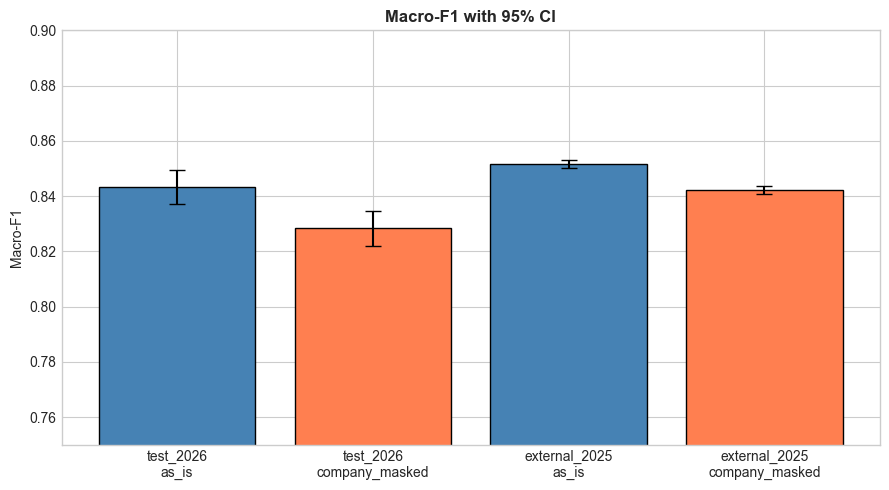

✓ Saved: 06_macro_f1_ci.png


In [4]:
print(metrics.to_string(index=False))
def ci(s):
    lo, hi = s.strip('[]').split(';')
    return float(lo), float(hi)
fig, ax = plt.subplots(figsize=(9, 5))
labels = metrics['dataset'] + '\n' + metrics['variant']
lo = np.array([ci(s)[0] for s in metrics['macro_f1_ci95']]); hi = np.array([ci(s)[1] for s in metrics['macro_f1_ci95']])
ax.bar(labels, metrics['macro_f1'], yerr=[metrics['macro_f1'] - lo, hi - metrics['macro_f1']], capsize=6,
       color=['steelblue', 'coral'] * 2, edgecolor='black')
ax.set_ylim(0.75, 0.9); ax.set_ylabel('Macro-F1')
ax.set_title('Macro-F1 with 95% CI', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('output/06_macro_f1_ci.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 06_macro_f1_ci.png')

## 2. Brand-Name Dependency (paired bootstrap)

In [5]:
print(gap.to_string(index=False))
print('\nLower bound: masking is incomplete (brands absent from the Company column stay visible).')

      dataset  gap_as_is_minus_masked          gap_ci95
    test_2026                  0.0152 [0.0115 ; 0.0186]
external_2025                  0.0093 [0.0085 ; 0.0101]

Lower bound: masking is incomplete (brands absent from the Company column stay visible).


## 3. Recall by Service — company_masked

dataset                   external_2025  test_2026
service                                           
Comptes & Dépôts                 0.8323     0.8118
Crédit immobilier                0.8794     0.9091
Crédits aux particuliers         0.8068     0.8280
Monétique                        0.7818     0.8216
Recouvrement                     0.9165     0.9169
Transferts & Paiements           0.7978     0.6482


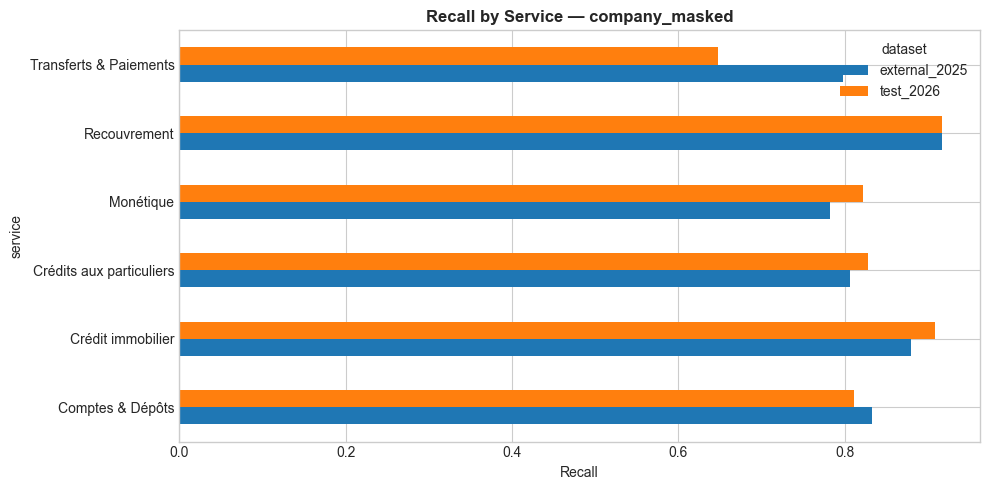

✓ Saved: 06_recall_by_service.png


In [6]:
r = ps[ps['variant'] == 'company_masked'].pivot(index='service', columns='dataset', values='recall')
print(r.round(4).to_string())
ax = r.plot.barh(figsize=(10, 5))
ax.set_title('Recall by Service — company_masked', fontsize=12, fontweight='bold'); ax.set_xlabel('Recall')
plt.tight_layout()
plt.savefig('output/06_recall_by_service.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 06_recall_by_service.png')

## 4. Calibration

      dataset        variant    ece  brier
    test_2026          as_is 0.0332 0.2256
    test_2026 company_masked 0.0338 0.2414
external_2025          as_is 0.0359 0.2250
external_2025 company_masked 0.0381 0.2358


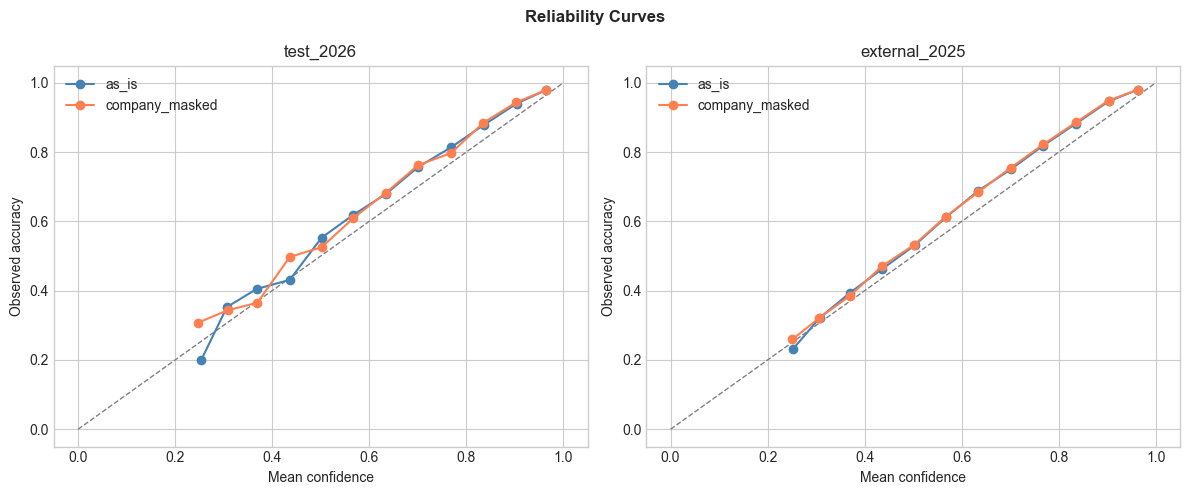

✓ Saved: 06_reliability.png


In [7]:
print(cal.to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, ds in zip(axes, ['test_2026', 'external_2025']):
    ax.plot([0, 1], [0, 1], '--', color='grey', lw=1)
    for v, color in [('as_is', 'steelblue'), ('company_masked', 'coral')]:
        t = pd.read_csv(f'reports/phase3c/reliability_{ds}_{v}.csv')
        ax.plot(t['mean_confidence'], t['accuracy'], marker='o', label=v, color=color)
    ax.set_title(ds); ax.set_xlabel('Mean confidence'); ax.set_ylabel('Observed accuracy'); ax.legend()
fig.suptitle('Reliability Curves', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('output/06_reliability.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 06_reliability.png')

## 5. Test Confusion Matrix — company_masked

                          Comptes & Dépôts  Crédit immobilier  Crédits aux particuliers  Monétique  Recouvrement  Transferts & Paiements
Comptes & Dépôts                      2593                  7                        28        234            49                     283
Crédit immobilier                       15               1060                        58         17            15                       1
Crédits aux particuliers                55                 11                      1772        100           187                      15
Monétique                              256                  8                        54       2671           194                      68
Recouvrement                            59                 25                       156        138          4339                      15
Transferts & Paiements                 391                  6                        14         89            15                     949


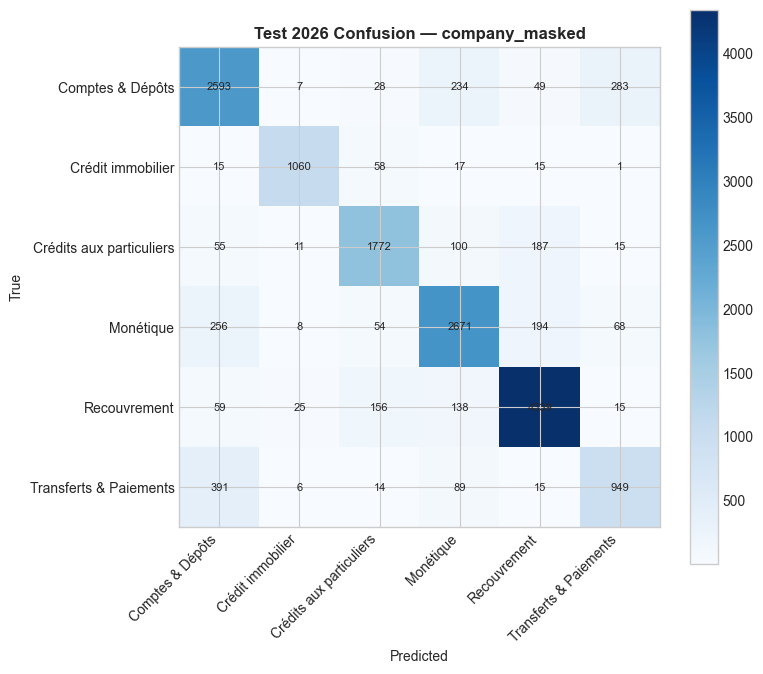

✓ Saved: 06_test_confusion.png


In [8]:
cm = pd.read_csv('reports/phase3c/confusion_test_2026_company_masked.csv', index_col=0)
print(cm.to_string())
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm.values, cmap='Blues')
ax.set_xticks(range(len(cm)), cm.columns, rotation=45, ha='right'); ax.set_yticks(range(len(cm)), cm.index)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, cm.values[i, j], ha='center', va='center', fontsize=8)
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); fig.colorbar(im, ax=ax)
ax.set_title('Test 2026 Confusion — company_masked', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('output/06_test_confusion.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 06_test_confusion.png')

## 6. Error Analysis

In [9]:
print('Most confused pairs (test 2026):')
print(pd.read_csv('reports/phase3c/top_confused_pairs.csv').to_string(index=False))
hc = pd.read_csv('reports/phase3c/high_confidence_errors.csv')
print(f'\nHigh-confidence errors (examples, label-noise candidates): {len(hc)} shown')
for _, r in hc.head(5).iterrows():
    print(f"  [{r['service']} -> {r['pred']}, conf {r['confidence']:.2f}] {str(r['text_300'])[:150]}…")

Most confused pairs (test 2026):
                 service                   pred  n_errors  share_of_true_service_pct
  Transferts & Paiements       Comptes & Dépôts       391                      26.71
        Comptes & Dépôts Transferts & Paiements       283                       8.86
               Monétique       Comptes & Dépôts       256                       7.87
        Comptes & Dépôts              Monétique       234                       7.33
               Monétique           Recouvrement       194                       5.97
Crédits aux particuliers           Recouvrement       187                       8.74

High-confidence errors (examples, label-noise candidates): 15 shown
  [Monétique -> Recouvrement, conf 0.99] I am filing this complaint against Midland Credit Management [REDACTED] regarding an alleged debt currently showing a balance of [AMOUNT] . The origin…
  [Recouvrement -> Crédit immobilier, conf 0.99] On [REDACTED] I bought my home [REDACTED] bought the mortgage

## 7. External 2025 — Monthly Macro-F1

received_month     n  macro_f1
       2025-01 46086    0.8567
       2025-02 17733    0.8363
       2025-03 17942    0.8254
       2025-04 17315    0.8226
       2025-05 18876    0.8244
       2025-06 18703    0.8205
       2025-07 21276    0.8211
       2025-08 20623    0.8133
       2025-09 19791    0.8018
       2025-10 18056    0.8233
       2025-11 18920    0.8213
       2025-12 16067    0.8256


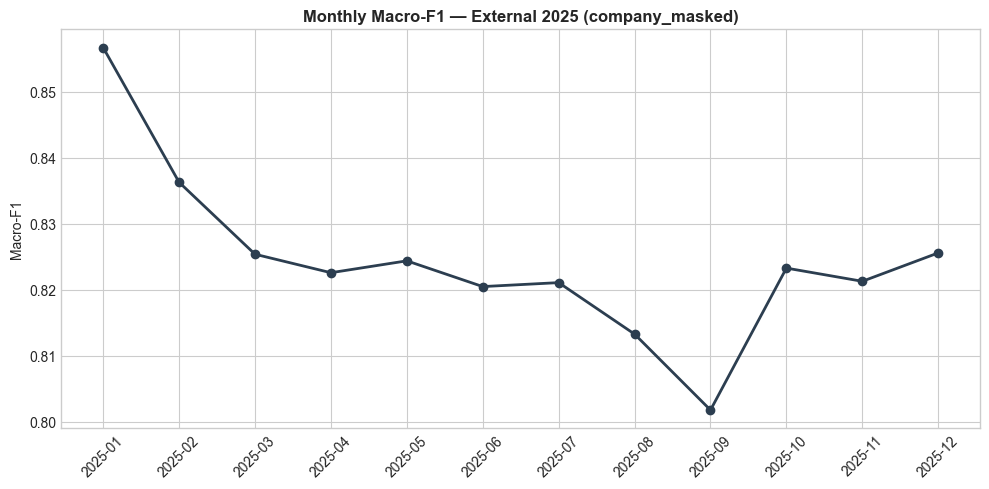

✓ Saved: 06_monthly_macro_f1_2025.png


In [10]:
m = pd.read_csv('reports/phase3c/monthly_macro_f1_external_2025_company_masked.csv')
print(m.to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(m['received_month'], m['macro_f1'], marker='o', linewidth=2, color='#2c3e50')
ax.set_title('Monthly Macro-F1 — External 2025 (company_masked)', fontsize=12, fontweight='bold')
ax.set_ylabel('Macro-F1'); ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('output/06_monthly_macro_f1_2025.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 06_monthly_macro_f1_2025.png')